# Exploration : obscurité du ciel (table astronomique)

Table `astronomy_hourly`, calculée avec PyEphem (aucune collecte) : hauteur du Soleil, phase de la nuit,
hauteur et éclairement de la Lune, nuit polaire, pour chaque lieu et chaque heure, de 2010 à 10 jours
après la date du calcul. Une aurore ne se voit que si le ciel est assez noir : Soleil sous -12°
(nuit nautique) au minimum, et Lune couchée ou peu éclairée pour les aurores faibles.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from auroracast.data import load

COLORS = {"tromso": "#2a78d6", "kiruna": "#eb6834", "rovaniemi": "#1baf7a"}
NAMES = {"tromso": "Tromsø", "kiruna": "Kiruna", "rovaniemi": "Rovaniemi"}
ORDER = ["tromso", "kiruna", "rovaniemi"]
MONTHS = ["janv", "févr", "mars", "avr", "mai", "juin", "juil", "août", "sept", "oct", "nov", "déc"]
MUTED, INK = "#52514e", "#0b0b0b"
SOURCE = "Calcul AuroraCast (PyEphem), heures UTC"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": "#e7e6e1", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

astro = load("astronomy_hourly")
astro["dark"] = astro["sun_alt_deg"] < -12
astro["dark_no_moon"] = astro["dark"] & (~astro["moon_up"] | (astro["moon_illum_pct"] < 25))
astro.tail(3)

,location,time,sun_alt_deg,night_phase,moon_alt_deg,moon_illum_pct,moon_up,polar_night,midnight_sun,source,dark,dark_no_moon
443187,rovaniemi,2026-11-08 07:00:00+00:00,0.42,day,1.86,1.2,True,False,False,calcul,False,False
443188,rovaniemi,2026-11-08 08:00:00+00:00,3.90,day,4.00,1.1,True,False,False,calcul,False,False
443189,rovaniemi,2026-11-08 09:00:00+00:00,6.11,day,4.81,1.0,True,False,False,calcul,False,False


## 1. Heures de ciel noir par jour, saison 2025-2026 (dernière saison complète)

Trait plein : heures avec le Soleil sous -12° (nuit nautique ou plus noire). Trait fin : parmi elles,
les heures sans gêne de la Lune (Lune couchée ou éclairée à moins de 25 %). Le creux régulier du trait
fin suit le cycle de la Lune (29,5 jours).

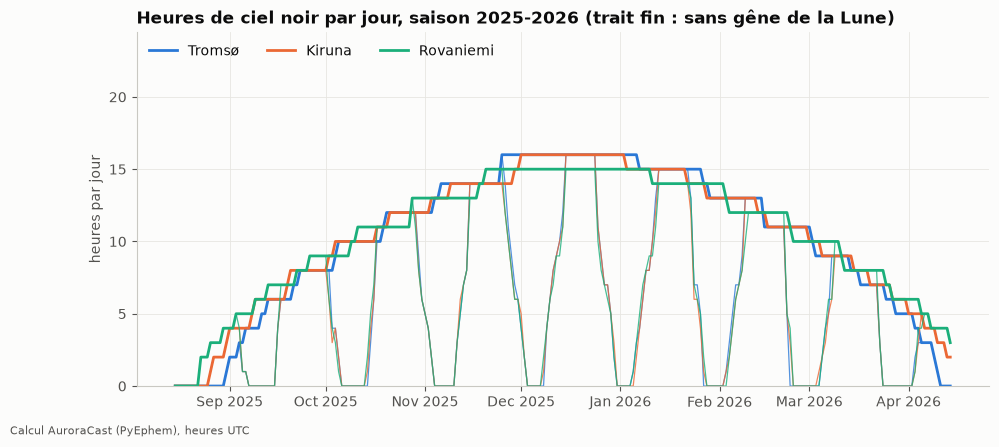

,premier jour,dernier jour,jours
location,,,
Kiruna,2025-12-11,2026-01-01,22
Tromsø,2025-11-27,2026-01-14,49


In [2]:
season = astro[(astro["time"] >= "2025-08-15") & (astro["time"] < "2026-04-15")].copy()
season["day"] = season["time"].dt.tz_localize(None).dt.normalize()
per_day = season.groupby(["location", "day"])[["dark", "dark_no_moon"]].sum().reset_index()

fig, ax = plt.subplots(figsize=(11, 4.6))
for loc in ORDER:
    g = per_day[per_day["location"] == loc]
    ax.plot(g["day"], g["dark"], color=COLORS[loc], linewidth=2, label=NAMES[loc])
    ax.plot(g["day"], g["dark_no_moon"], color=COLORS[loc], linewidth=0.9, alpha=0.8)
ax.set_ylim(0, 24.5)
ax.set_ylabel("heures par jour")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Heures de ciel noir par jour, saison 2025-2026 (trait fin : sans gêne de la Lune)")
ax.legend(frameon=False, loc="upper left", ncols=3)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color=MUTED)
plt.show()
polar = season[season["polar_night"]].assign(day=lambda d: d["time"].dt.date).groupby("location")["day"]
# Nuit polaire de la saison (jours UTC sans lever du Soleil)
pd.DataFrame({"premier jour": polar.min(), "dernier jour": polar.max(), "jours": polar.nunique()}).rename(index=NAMES)

Lecture : en plein hiver, les 3 lieux ont 14 à 17 heures de ciel noir par jour ; la nuit polaire
(Soleil jamais levé) ne concerne que Tromsø et, quelques jours, Kiruna. De mi-avril à mi-août, il ne
fait jamais assez noir : pas d'observation d'aurore possible, quelle que soit l'activité solaire.

## 2. Vérification : l'anomalie du ciel « dégagé » à Tromsø en janvier

Le notebook 02 montrait Tromsø plus souvent dégagé en janvier qu'en mars, ce qui surprend pour une
station côtière. Hypothèse : la nuit, il est plus difficile d'estimer les nuages. On compare la part de
ciel dégagé (0 à 2 octas) des observations faites de jour et de nuit (Soleil sous -12°).

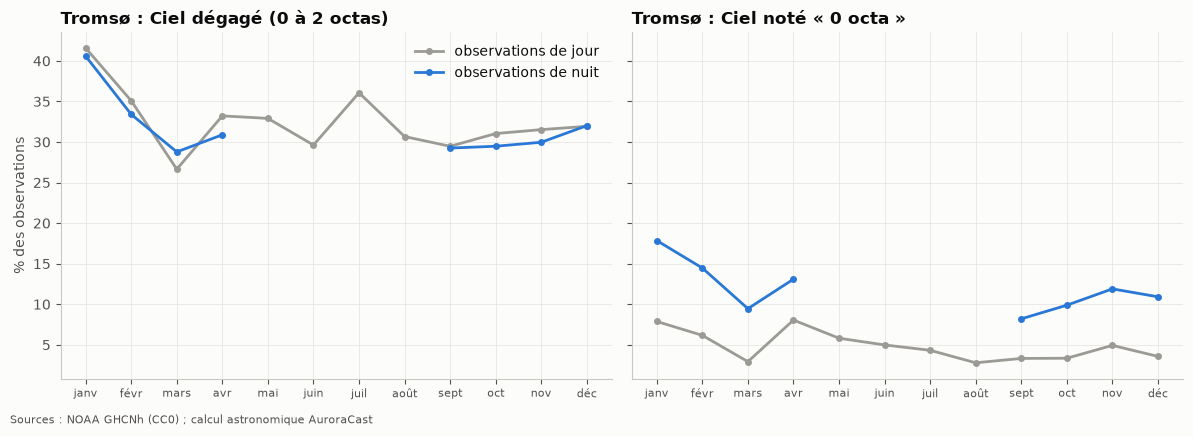

clear        zero      
dark  False True  False True 
month                        
1      41.6  40.6   7.9  17.9
2      35.1  33.4   6.2  14.5
3      26.7  28.8   2.9   9.5
4      33.2  30.9   8.1  13.1
5      32.9   NaN   5.8   NaN
6      29.6   NaN   5.0   NaN
7      36.1   NaN   4.3   NaN
8      30.7   NaN   2.8   NaN
9      29.5  29.3   3.3   8.2
10     31.0  29.5   3.3   9.9
11     31.5  30.0   4.9  11.9
12     31.9  32.0   3.6  10.9

In [3]:
clouds = load("cloud_hourly")
m = clouds[clouds["oktas"].notna()].merge(astro[["location", "time", "dark"]], on=["location", "time"])
t = m[m["location"] == "tromso"].assign(month=lambda d: d["time"].dt.month,
                                         clear=lambda d: d["oktas"] <= 2, zero=lambda d: d["oktas"] == 0)
share = t.pivot_table(index="month", columns="dark", values=["clear", "zero"], aggfunc="mean") * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, title in [(axes[0], "clear", "Ciel dégagé (0 à 2 octas)"), (axes[1], "zero", "Ciel noté « 0 octa »")]:
    for dark, color, label in [(False, "#9b9a95", "observations de jour"), (True, COLORS["tromso"], "observations de nuit")]:
        s = share[(col, dark)].reindex(range(1, 13))   # mois sans nuit noire : trou, pas de ligne
        ax.plot(s.index, s.values, color=color, linewidth=2, marker="o", markersize=4, label=label)
    ax.set_xticks(range(1, 13), MONTHS, fontsize=8)
    ax.set_title(f"Tromsø : {title}")
axes[0].set_ylabel("% des observations")
axes[0].legend(frameon=False, loc="upper right")
fig.text(0.01, -0.02, "Sources : NOAA GHCNh (CC0) ; calcul astronomique AuroraCast", fontsize=8, color=MUTED)
fig.tight_layout()
plt.show()
share.round(1)

Conclusion de la vérification :

- la part de ciel **dégagé (0 à 2 octas) est la même de jour et de nuit** à mois égal (41 à 42 % en
  janvier dans les deux cas) : l'obscurité **n'explique pas** que janvier paraisse plus dégagé que mars ;
  l'écart semble climatique et sera retesté avec les prévisions MET Norway ;
- en revanche, la nuit, la station note **« 0 octa » plus de 2 fois plus souvent** qu'en plein jour
  (18 % contre 8 % en janvier, et le même écart chaque mois) : de nuit, un ciel peu nuageux est noté complètement dégagé. Ce biais
  reste à l'intérieur de la catégorie « dégagé » ; règle retenue pour la suite : seuil **≤ 2 octas**,
  jamais « = 0 octa ».